# 06 · Training and tuning

**Why.** Start with an interpretable baseline, then test whether flexible models add anything. Logistic regression, random forest and XGBoost are tuned on the same five folds and compared with two yardsticks: no model, and the NIDDK/ADA paper risk checklist clinics already use.

**Re-run it** (about 20–25 minutes on a laptop):

```bash
diabetes-screening-model train --input data/derived/combined_BRFSS2015.csv \
  --provenance data/derived/combined_BRFSS2015.provenance.json \
  --split reports/modeling/combined/split --output outputs/combined/training
```

In [1]:
# Every notebook reads the committed aggregate reports, so it runs from a fresh clone without the survey data.
from pathlib import Path
import json

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ENDPOINT = "combined"  # "prediabetes" shows the sensitivity analysis instead
REPORTS = ROOT / "reports"
STAGE_1_4 = REPORTS / ("uploaded-combined" if ENDPOINT == "combined" else "prediabetes")
MODELING = REPORTS / "modeling" / ENDPOINT
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 100)


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def figure(path, width=860):
    display(Image(filename=str(path), width=width))

In [2]:
comparison = pd.read_csv(MODELING / "training" / "comparison.csv")
comparison[["model", "pr_auc_mean", "pr_auc_sd", "roc_auc_mean", "brier_mean", "precision_at_80_recall_mean",
            "flagged_share_at_80_recall_mean"]]

,model,pr_auc_mean,pr_auc_sd,roc_auc_mean,brier_mean,precision_at_80_recall_mean,flagged_share_at_80_recall_mean
0,no_model,0.158,1.288e-05,0.500,0.133,0.158,1.000
1,ada_checklist,0.325,4.344e-03,0.756,0.228,0.256,0.514
2,logistic_regression,0.439,7.202e-03,0.819,0.108,0.324,0.389
3,random_forest,0.456,6.701e-03,0.822,0.106,0.326,0.387
4,xgboost,0.461,6.342e-03,0.826,0.106,0.332,0.380


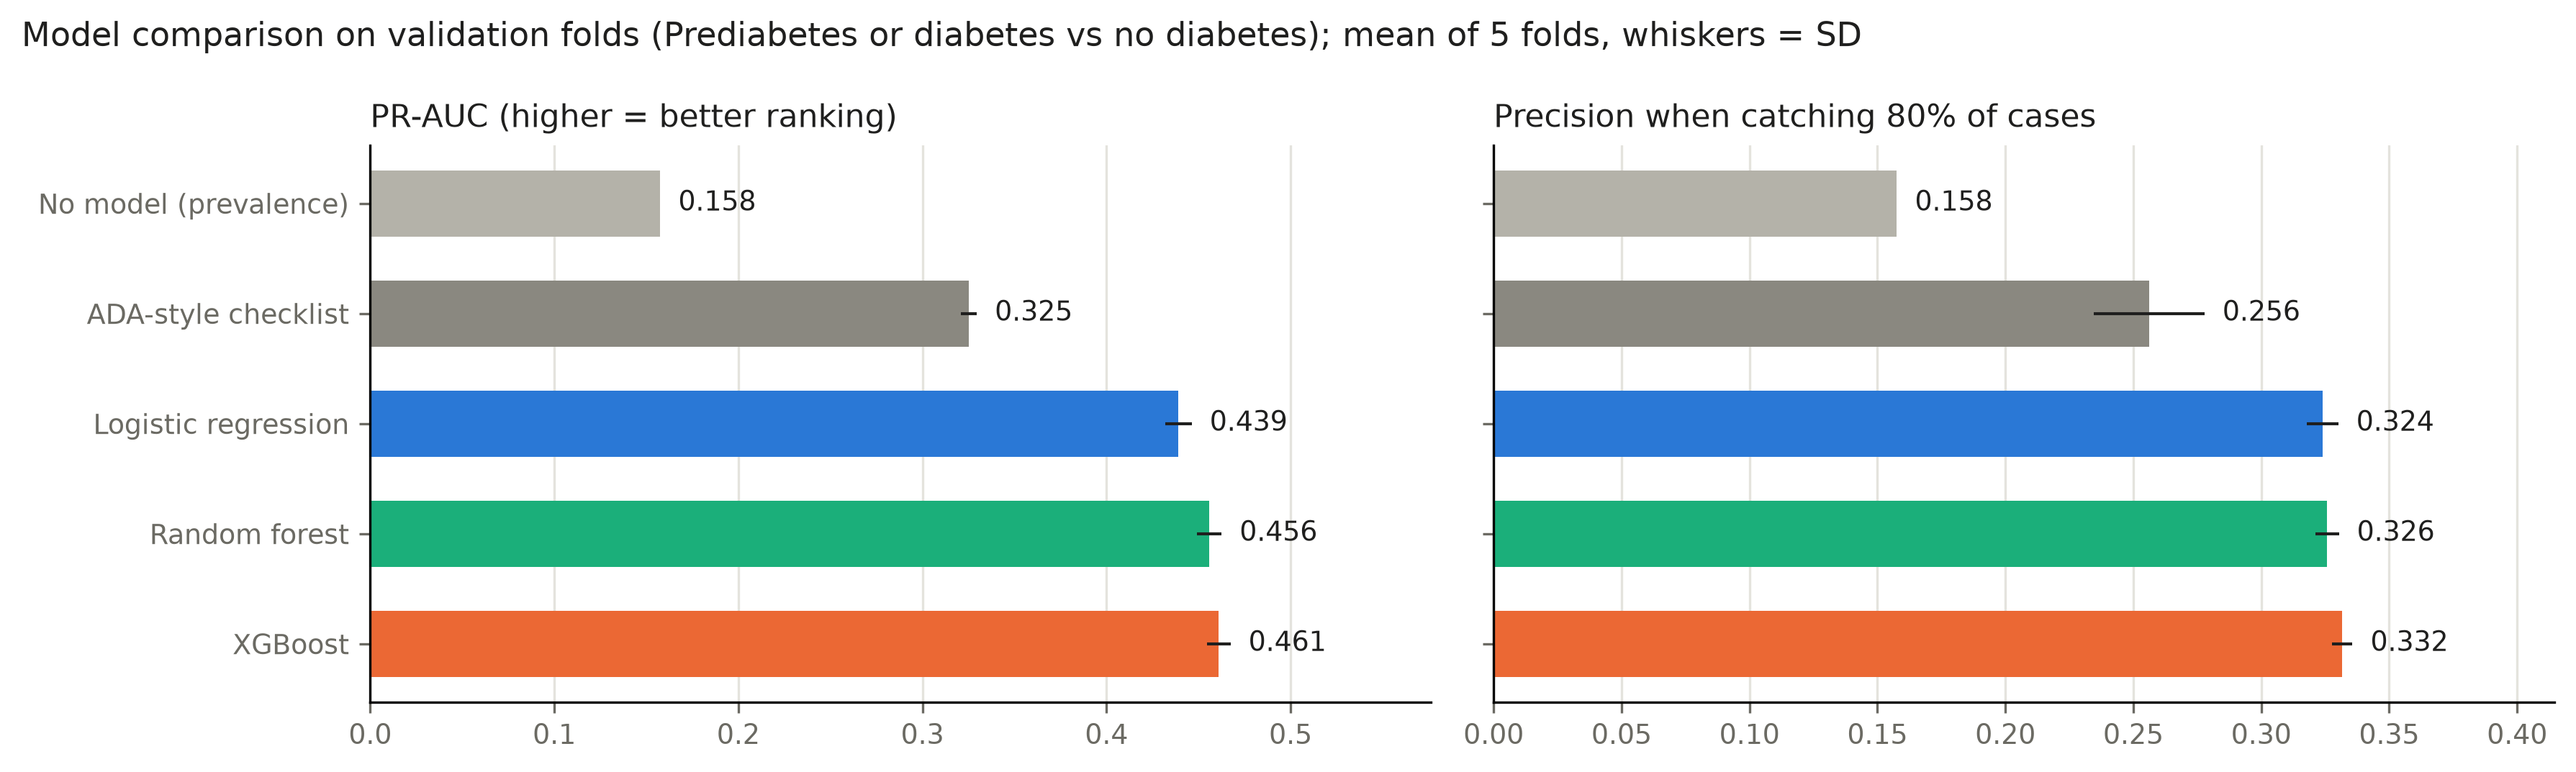

In [3]:
figure(MODELING / "training" / "comparison.png")

## Which model goes forward, and why

In [4]:
selection = read_json(MODELING / "training" / "selection.json")
print("Chosen:", selection["chosen"])
print("Reason:", selection["reason"])
pd.read_csv(MODELING / "training" / "paired_differences.csv")

Chosen: xgboost
Reason: highest mean validation PR-AUC (0.4610), ahead of Random forest by 0.0052 in 5 of 5 folds (corrected t-test p = 0.005)


,model,compared_with,mean_pr_auc_gain,sd_pr_auc_gain,folds_won,folds,corrected_t,p_value
0,logistic_regression,ada_checklist,0.114,0.004,5,5,38.038,2.853e-06
1,random_forest,ada_checklist,0.131,0.003,5,5,62.846,3.840e-07
2,xgboost,ada_checklist,0.136,0.003,5,5,59.613,4.742e-07
3,random_forest,logistic_regression,0.017,0.002,5,5,10.741,4.259e-04
4,xgboost,logistic_regression,0.022,0.002,5,5,15.282,1.069e-04
5,xgboost,random_forest,0.005,0.001,5,5,5.638,4.870e-03


## The tuned pipeline

The fitted pipelines are committed, so they can be loaded without the data. `load_pipeline` also handles XGBoost models pickled on another operating system.

In [5]:
from diabetes_screening.modeling.training_workflow import load_pipeline

pipeline = load_pipeline(MODELING / "training" / "models" / f"{selection['chosen']}.joblib")
settings = pipeline.named_steps["model"].get_params()
pd.Series({k: settings[k] for k in ["n_estimators", "learning_rate", "max_depth", "min_child_weight", "subsample",
                                    "colsample_bytree", "reg_lambda"] if k in settings}).to_frame("tuned value")

,tuned value
n_estimators,800.000
learning_rate,0.058
max_depth,3.000
min_child_weight,25.000
subsample,0.706
colsample_bytree,0.640
reg_lambda,6.813


## What drives the predictions

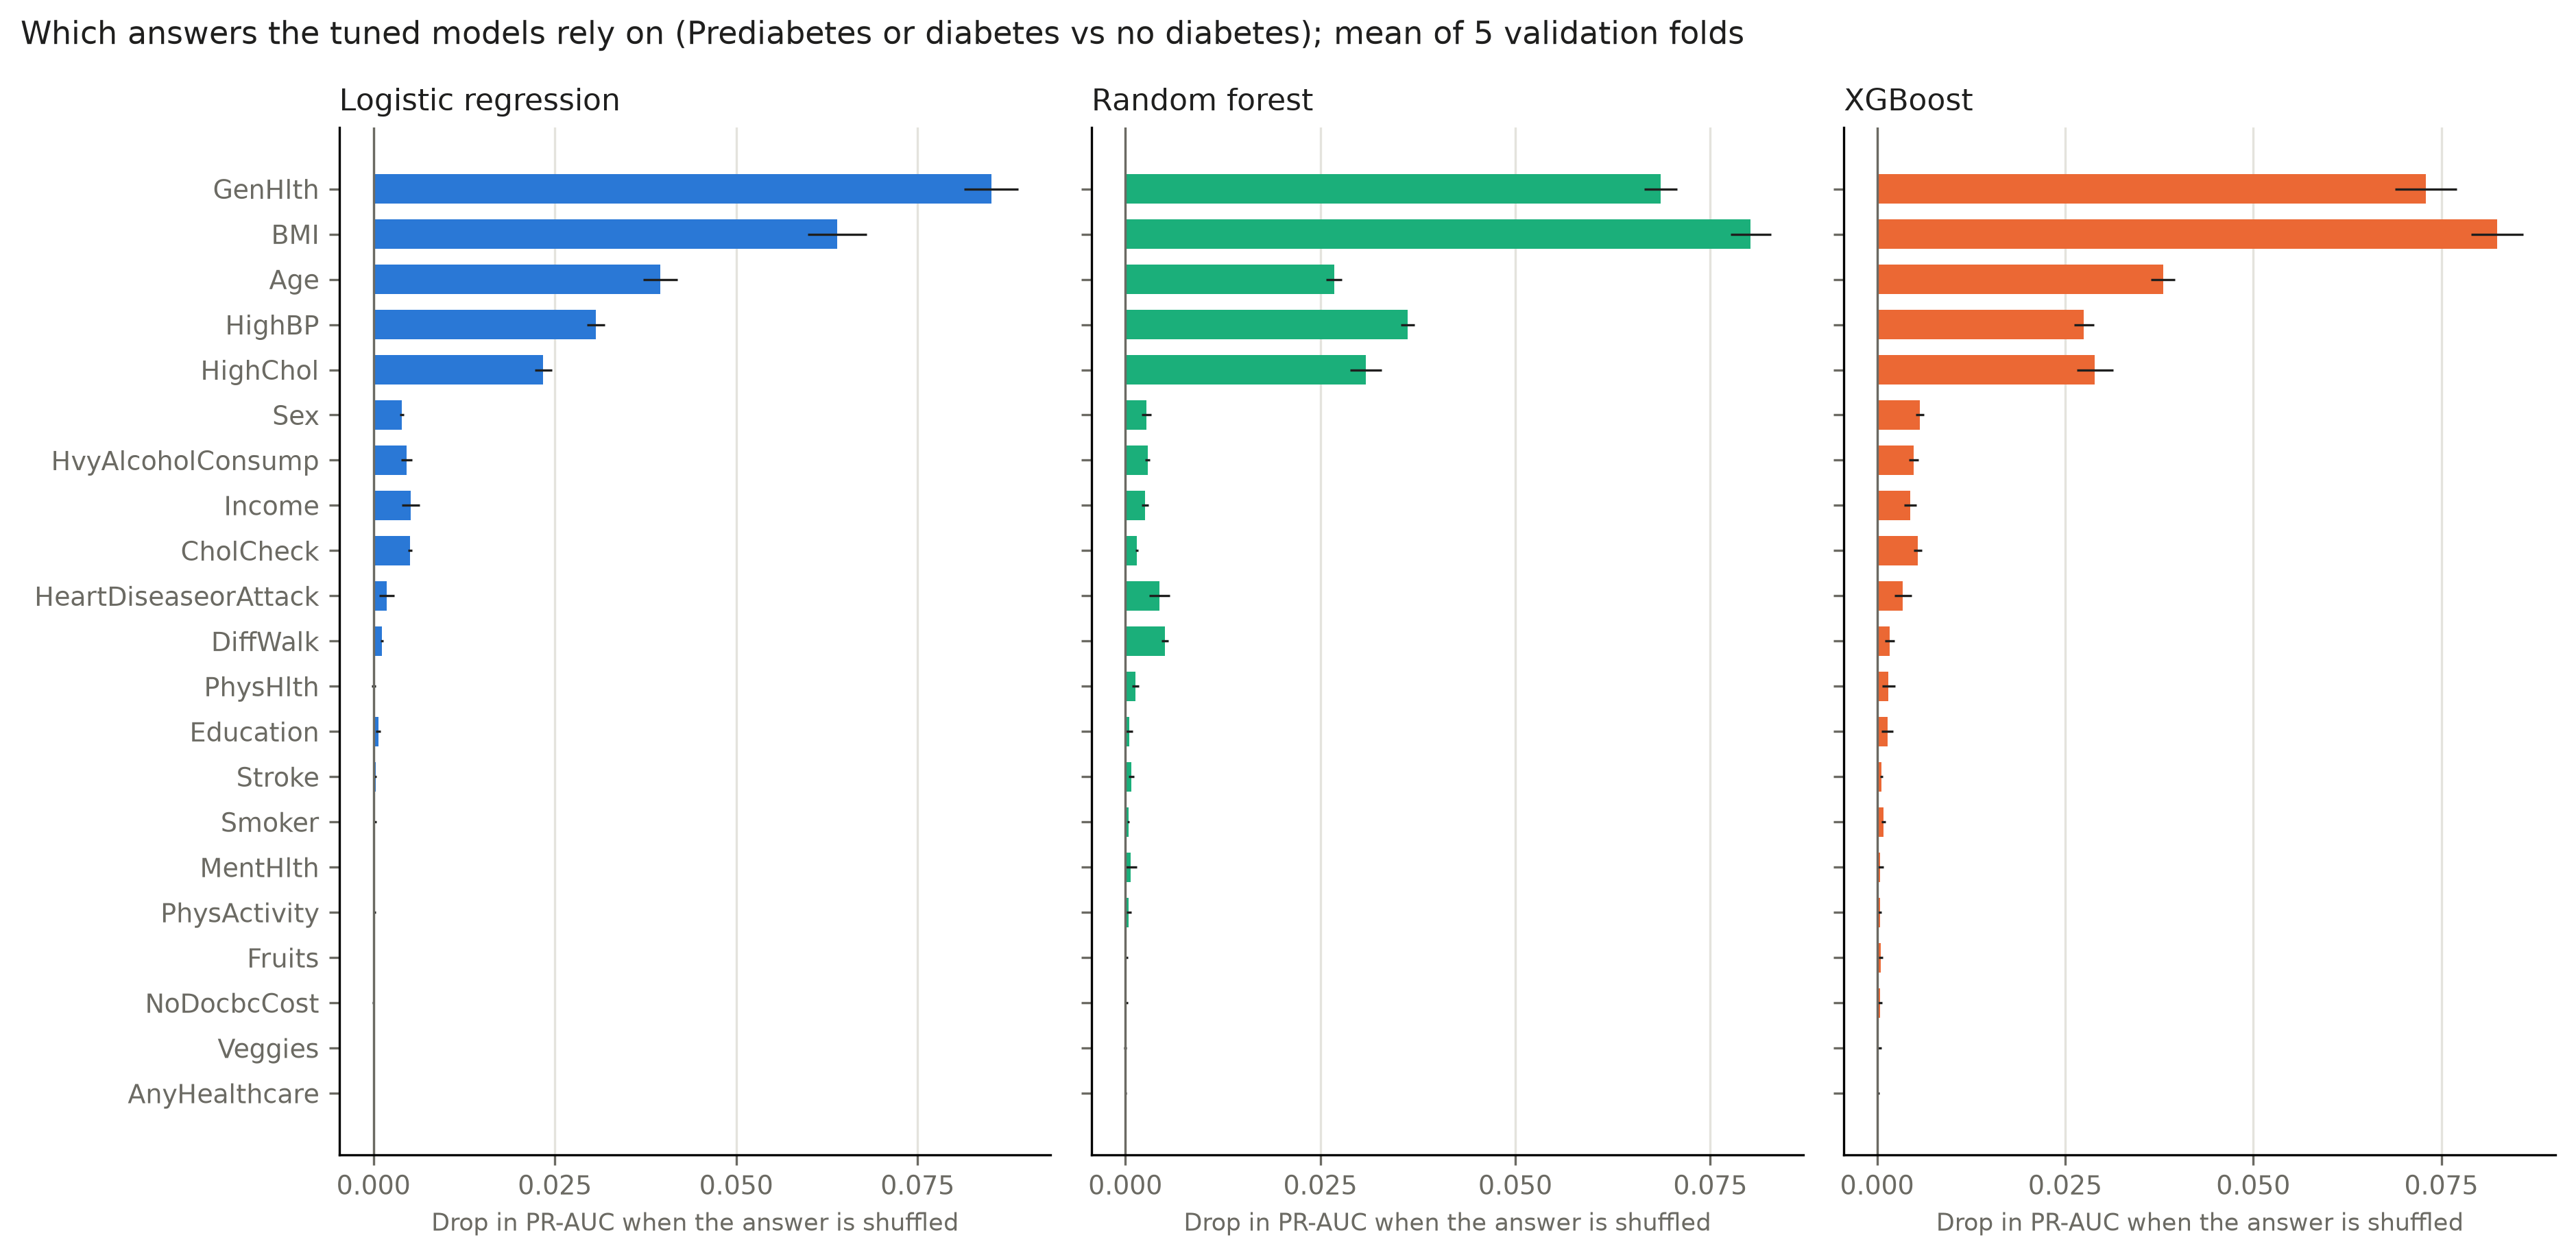

In [6]:
figure(MODELING / "training" / "permutation_importance.png")

## Adjusted odds ratios (statsmodels)

One logistic regression with all 21 answers, on training rows only. `change_after_adjustment` flags associations from stage 4 that weaken, vanish or reverse once everything else is held fixed.

In [7]:
odds = pd.read_csv(MODELING / "training" / "odds_ratios.csv")
odds[["feature", "unit", "unadjusted_or", "adjusted_or", "adjusted_ci_low", "adjusted_ci_high",
      "change_after_adjustment", "vif"]].sort_values("adjusted_or", ascending=False)

,feature,unit,unadjusted_or,adjusted_or,adjusted_ci_low,adjusted_ci_high,change_after_adjustment,vif
2,CholCheck,yes vs no,5.888,3.329,2.907,3.812,weaker,1.034
0,HighBP,yes vs no,4.777,2.028,1.967,2.091,weaker,1.332
1,HighChol,yes vs no,3.231,1.810,1.760,1.862,weaker,1.172
13,GenHlth,per step toward 'poor',2.169,1.679,1.651,1.708,weaker,1.793
17,Sex,male vs female,1.177,1.273,1.238,1.309,stronger,1.075
6,HeartDiseaseorAttack,yes vs no,3.485,1.218,1.173,1.266,weaker,1.171
18,Age,per 5-year age band,1.206,1.137,1.130,1.143,weaker,1.349
16,DiffWalk,yes vs no,3.682,1.104,1.065,1.144,weaker,1.532
5,Stroke,yes vs no,2.886,1.076,1.020,1.136,weaker,1.081
12,NoDocbcCost,yes vs no,1.397,1.070,1.019,1.122,weaker,1.143


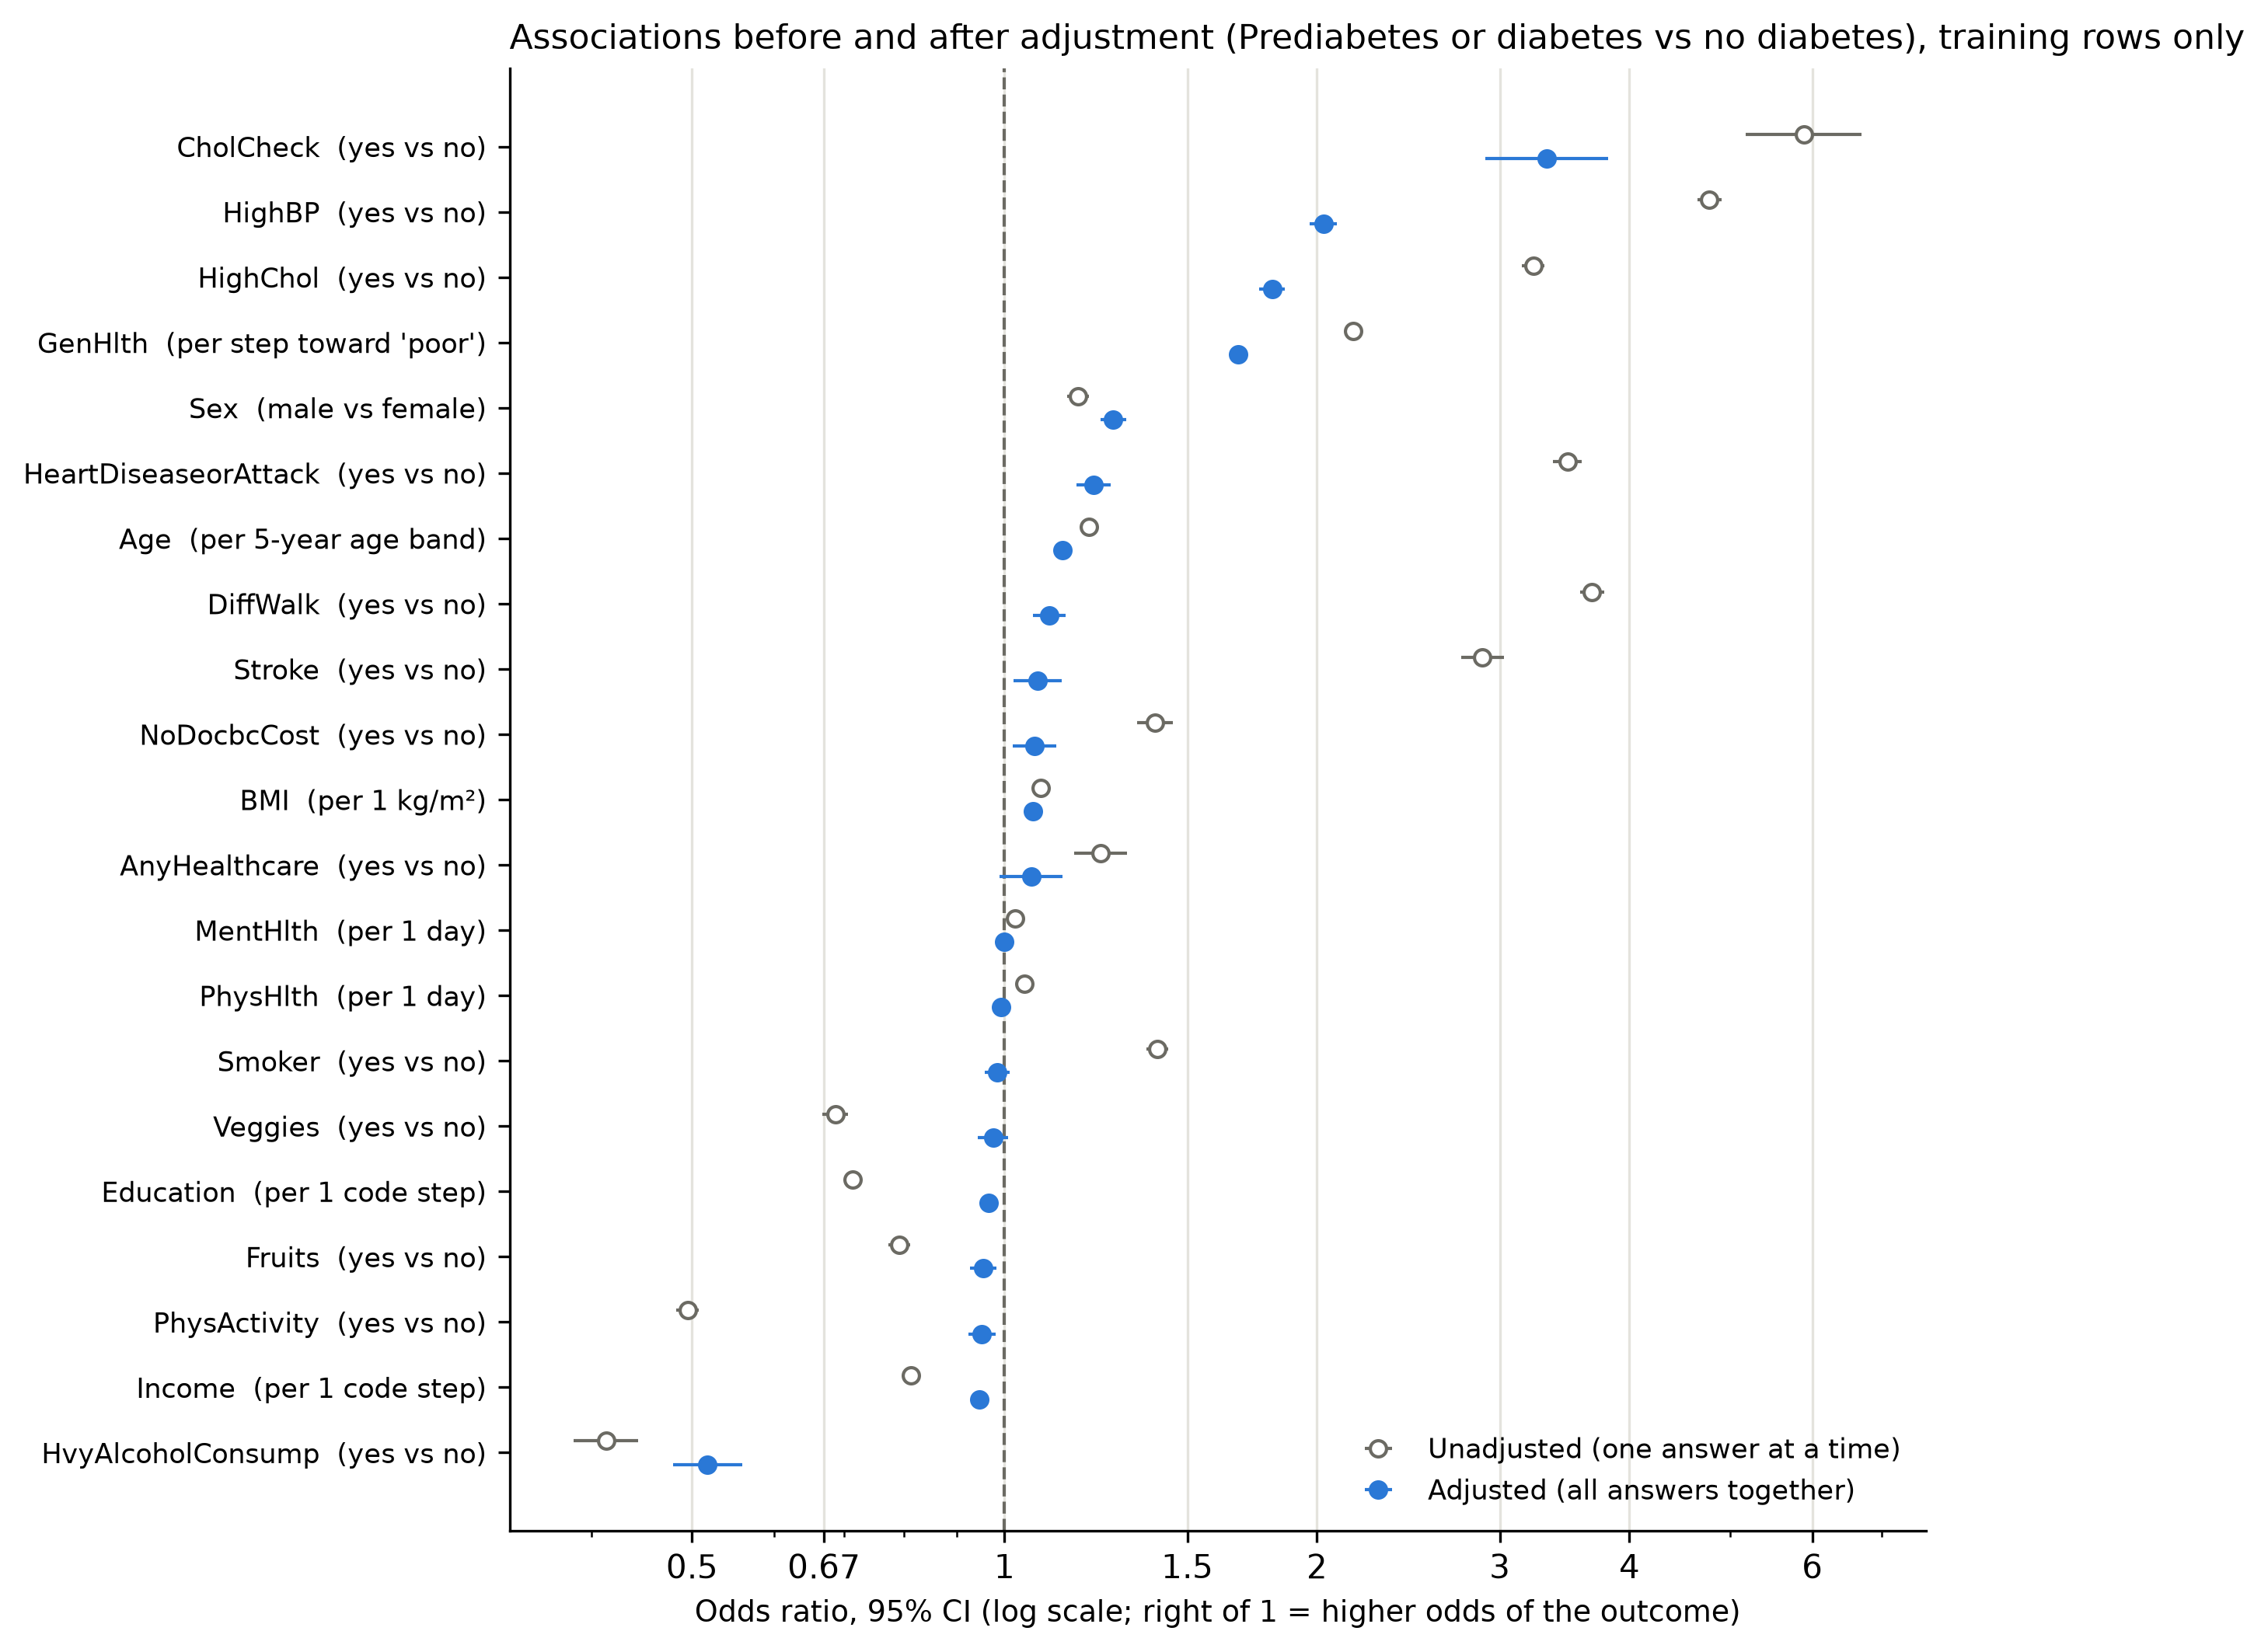

In [8]:
figure(MODELING / "training" / "odds_ratios.png")

**Takeaway.** Every model clearly beats the checklist, and XGBoost edges out the others in all five folds. BMI, general health, age, high blood pressure and high cholesterol carry most of the signal. Physical-health days reverse after adjustment, and smoking and vegetables lose their association: a warning against reading single-answer comparisons as effects. Write-up: [training](../docs/training.md).

This is a research prototype for risk stratification, not a diagnostic or clinical decision tool. The outcome is self-reported, the data are cross-sectional and unweighted, and associations are not causes.